# The effect of climate change on energy use in the United States, with real uncertainty

This notebook aggregates the effect of climate change on other_energy
use (fuels other than electricity) from impact regions to United
States states, at year 2099, with the parameter uncertainty the
sector actually carries: the delta method. Energy has no Monte Carlo
draws. Each file holds the gradient of the impact with respect to the
80 regression coefficients and their covariance matrix, so the
variance of any aggregate is one quadratic form away.

The sample is the restored 2020 delta-method tree: one fuel
(other_energy), all 33 climate models, rcp85, SSP3, high income
scenario, full adaptation minus histclim. The numbers are a
demonstration, not results.

In [1]:
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm

sys.path.insert(0, ".")
import compute
import cil_regionalization as cilreg

states = gpd.read_parquet(compute.DATA / "usa_adm1_plot.parquet")
regions, gcms, effects, vcv, gammas, factor, population = compute.load_static()
weights = compute.load_weights()
print(len(states), "states;", len(gcms), "climate models;", len(regions), "regions")

51 states; 33 climate models; 3151 regions


## The variable and its units

The files store `rebased`, the impact relative to the scenario's own
2001 to 2010 average. Two labels in the files are stale. The physical
unit is GJ per capita, not the kWh/pc the metadata says. The dollar
files understate by exactly 0.0036, because a GJ quantity was
multiplied by a per-kWh price; `compute.GJ_PER_KWH` repairs it. The
effect of climate change is the file minus its `-histclim` sibling,
with no adaptation the exception, as in the other sectors.

In a delta-method file the `rebased` variable holds the variance and
`rebased_bcde` holds the gradient. The committed pair below is
unmodified CCSM4 output; the check that the stored variance equals
the quadratic form runs on it directly.

In [2]:
with __import__("netCDF4").Dataset(compute.DATA / "pair_ccsm4.nc4") as ds:
    g_full = np.asarray(ds.variables["fulladapt_bcde"][:], dtype="float64")
    g_hist = np.asarray(ds.variables["histclim_bcde"][:], dtype="float64")
    var_full = np.asarray(ds.variables["fulladapt_variance"][:])
    pair_vcv = np.asarray(ds.variables["vcv"][:])

quad = np.einsum("cr,cd,dr->r", g_full, pair_vcv, g_full)
err = np.nanmax(np.abs(quad - var_full) / np.nanmax(var_full))
print(f"stored variance against the quadratic form: largest difference {err:.1e}")

effect_ccsm4 = g_full - g_hist
i = gcms.index("CCSM4")
print(f"matches the committed effect gradient: "
      f"{np.allclose(effect_ccsm4, effects[i], atol=1e-6 * np.abs(effects[i]).max())}")

stored variance against the quadratic form: largest difference 1.4e-07
matches the committed effect gradient: True


## Dollars by state

The valued gradient is the physical gradient times population times
the price. The price is the price014 scenario, 1.4 percent annual
growth, recovered from the tree's own price014 files: the two years
checked grow at exactly that rate. Aggregating with the `per_source`
weights and taking the quadratic form gives each state's mean and
standard deviation, deflated to 2019 USD (the raw files are 2005
USD). The mean is the gradient times the coefficient vector, exact
because the response is linear in the coefficients.

In [3]:
i = gcms.index("CCSM4")
val = compute.valued_states(weights, regions, effects[i], vcv, gammas, factor)
val = val.merge(states[["ISO", "ID_1", "NAME_1"]], on=["ISO", "ID_1"])
val[["mean_b", "sd_b"]] = val[["mean", "sd"]] / 1e9
print("one model (CCSM4), 2099, billion 2019 USD; largest mean effects:")
print(val.reindex(val["mean_b"].abs().sort_values(ascending=False).index)
      [["NAME_1", "mean_b", "sd_b"]].head(8).round(2).to_string(index=False))

one model (CCSM4), 2099, billion 2019 USD; largest mean effects:
      NAME_1  mean_b  sd_b
  California   -5.58  1.16
    New York   -4.38  0.77
    Illinois   -3.54  0.59
    Michigan   -3.25  0.58
       Texas   -2.98  0.84
        Ohio   -2.94  0.51
Pennsylvania   -2.76  0.50
   Wisconsin   -2.02  0.36


## The point of the gradients

Every region's impact moves with the same 80 estimated coefficients,
so regional errors are correlated, and the correlation survives
aggregation. Summing independently drawn region values instead treats
them as uncorrelated. The table compares each state's standard
deviation computed both ways, for one model.

In [4]:
naive = compute.naive_valued_sd(weights, regions, effects[i], vcv, factor)
cmp = (val[["ISO", "ID_1", "NAME_1", "sd"]]
       .merge(naive.rename(columns={"sd": "sd_naive"}), on=["ISO", "ID_1"]))
cmp["ratio"] = cmp["sd"] / cmp["sd_naive"]
print("state sd, correct against independent-regions, billion 2019 USD:")
show = cmp.nlargest(6, "sd")[["NAME_1", "sd", "sd_naive", "ratio"]]
show[["sd", "sd_naive"]] = show[["sd", "sd_naive"]] / 1e9
print(show.round(2).to_string(index=False))
print(f"\nmedian understatement factor across states: {cmp['ratio'].median():.1f}")

state sd, correct against independent-regions, billion 2019 USD:
    NAME_1   sd  sd_naive  ratio
California 1.16      0.38   3.10
     Texas 0.84      0.20   4.29
  New York 0.77      0.18   4.35
  Illinois 0.59      0.25   2.33
  Michigan 0.58      0.14   4.21
      Ohio 0.51      0.11   4.59

median understatement factor across states: 3.6


## Physical and valued, mapped

The physical effect is GJ per capita, a population-weighted mean over
each state's regions. The heating gradient shows: northern states
save fuel, southern states barely move. Higher spending is red,
savings are blue.

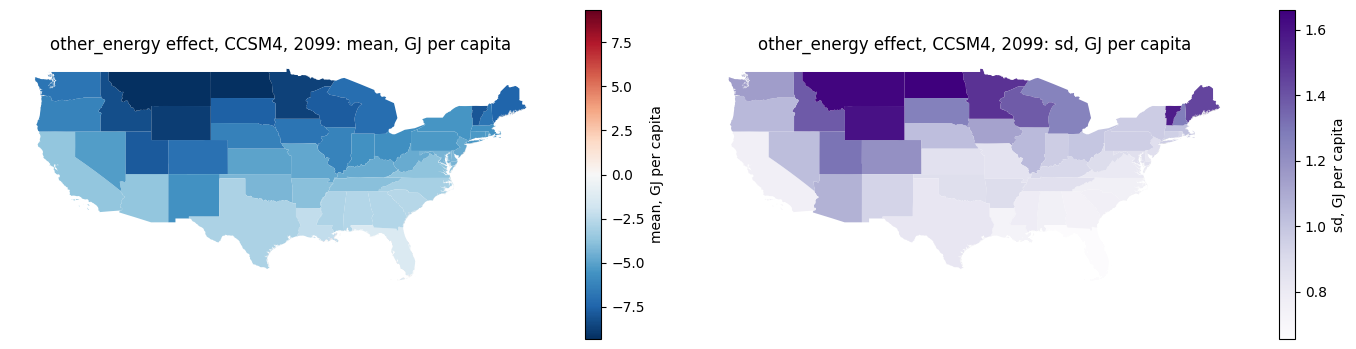

In [5]:
phys = compute.physical_states(weights, regions, effects[i], vcv, gammas, population)
m = states.merge(phys, on=["ISO", "ID_1"])
main = m[~m["NAME_1"].isin(["Alaska", "Hawaii"])]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, label in ((axes[0], "mean", "mean, GJ per capita"),
                       (axes[1], "sd", "sd, GJ per capita")):
    lim = float(np.abs(main[col]).max())
    norm = TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim) if col == "mean" else None
    main.plot(column=col, ax=ax, cmap="RdBu_r" if col == "mean" else "Purples",
              norm=norm, legend=True, legend_kwds={"label": label, "shrink": 0.7})
    ax.set_title(f"other_energy effect, CCSM4, 2099: {label}")
    ax.set_axis_off()
plt.tight_layout()

## Across the climate models

Each model contributes a normal distribution per state; the SMME
weights (doi:10.5281/zenodo.22003542) mix them. The map shows the
mixture mean; the table adds the 5th and 95th of the mixture, which
carry both climate spread and coefficient uncertainty.

largest mixture means, billion 2019 USD:
      NAME_1  mean   q05   q95
  California -5.45 -9.33 -2.41
    New York -5.35 -8.13 -3.32
    Illinois -3.91 -6.10 -2.34
       Texas -3.76 -7.19 -1.50
    Michigan -3.65 -5.67 -2.22
        Ohio -3.40 -5.15 -2.08
Pennsylvania -3.31 -5.00 -2.05
   Wisconsin -2.20 -3.47 -1.29


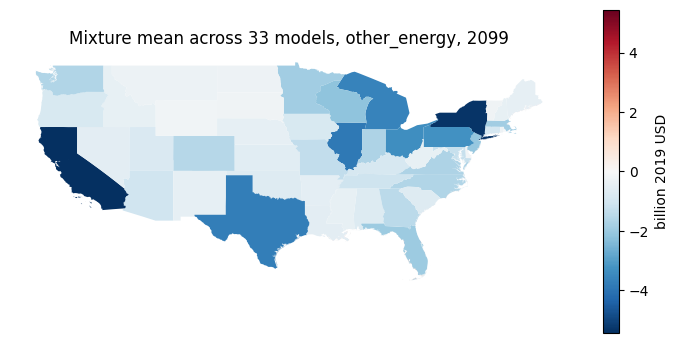

In [6]:
smme = pd.read_csv(
    "https://zenodo.org/records/22003542/files/rcp85_SMME_weights.tsv?download=1",
    sep="\t",
)[["model", "weight"]]
smme["key"] = smme["model"].str.replace("*", "", regex=False).str.lower()
keys = [g.replace("surrogate_", "").lower() for g in gcms]
w = smme.set_index("key")["weight"].reindex(keys).values
assert not np.isnan(w).any()

per_model = []
for k, gcm in enumerate(gcms):
    v = compute.valued_states(weights, regions, effects[k], vcv, gammas, factor)
    per_model.append(v.assign(gcm=gcm))
allm = pd.concat(per_model, ignore_index=True)

rows = []
for (iso, id1), grp in allm.groupby(["ISO", "ID_1"]):
    grp = grp.set_index("gcm").reindex(gcms)
    mean = float((grp["mean"] * w).sum() / w.sum())
    q05, q95 = cilreg.mixture_quantile(w, grp["mean"], grp["sd"] ** 2, [0.05, 0.95])
    rows.append({"ISO": iso, "ID_1": id1, "mean": mean, "q05": q05, "q95": q95})
mix = pd.DataFrame(rows)

mm = states.merge(mix, on=["ISO", "ID_1"])
main = mm[~mm["NAME_1"].isin(["Alaska", "Hawaii"])]
lim = float(np.abs(main["mean"]).max() / 1e9)
ax = main.assign(b=main["mean"] / 1e9).plot(
    column="b", cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim),
    legend=True, figsize=(9, 6),
    legend_kwds={"label": "billion 2019 USD", "shrink": 0.7})
ax.set_title("Mixture mean across 33 models, other_energy, 2099")
ax.set_axis_off()

tab = mix.merge(states[["ISO", "ID_1", "NAME_1"]], on=["ISO", "ID_1"])
for c in ("mean", "q05", "q95"):
    tab[c] = tab[c] / 1e9
print("largest mixture means, billion 2019 USD:")
print(tab.reindex(tab["mean"].abs().sort_values(ascending=False).index)
      [["NAME_1", "mean", "q05", "q95"]].head(8).round(2).to_string(index=False))

## What this does not cover

One fuel: the electricity gradients were not restored from the
archive. Total energy needs both fuels' gradients stacked,
other_energy first, against the release's 160 by 160 covariance
matrix. `cilreg pipeline` does not read gradient trees;
`aggregate_gradient` and `delta_method` are the route.